In [33]:
!pip install pymorphy3

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import pymorphy3
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from collections import Counter

# Загружаем данные
df = pd.read_csv('reviews.csv')
print(df.head())
print(f"Размер датасета: {df.shape}")
print(f"Пропуски в тексте: {df['text'].isna().sum()}")

   id                                               text  rating
0   1  Отличный фильм! Сюжет захватывает с первых мин...       9
1   2  Скучно и затянуто, еле досмотрел до конца. Бол...       2
2   3  Превосходная игра актёров! Особенно главный ге...      10
3   4  УЖАСНЫЙ СЦЕНАРИЙ, ничего не понятно. Потратил ...       1
4   5  Замечательная режиссура и красивые пейзажи. См...       8
Размер датасета: (25, 3)
Пропуски в тексте: 0


### Задание 1. Очистка и лемматизация
**Что делаем:** Пишем функцию `clean_text`, которая убирает весь цифровой и символьный мусор, оставляя только русские буквы и пробелы. Затем применяем лемматизацию через `pymorphy3`, чтобы превратить слова в начальную форму (например, "красивые" -> "красивый").

In [34]:
# Инициализируем лемматизатор
morph = pymorphy3.MorphAnalyzer()

def clean_text(text):
    text = text.lower() # В нижний регистр
    text = re.sub(r'http\S+|www.\S+', '', text) # Удаляем ссылки
    text = re.sub(r'<.*?>', '', text) # Удаляем HTML теги
    text = re.sub(r'#\w+', '', text) # Удаляем хэштеги
    text = re.sub(r'\d+', '', text) # Удаляем цифры
    text = re.sub(r'[^а-яё ]', '', text) # Оставляем только русские буквы и пробелы
    text = re.sub(r'\s+', ' ', text).strip() # Убираем лишние пробелы
    return text

def lemmatize_text(text):
    words = text.split()
    # Берем первый (самый вероятный) разбор слова и ставим в начальную форму
    lemmas = [morph.parse(word)[0].normal_form for word in words]
    return ' '.join(lemmas)

# Применяем функции
df['text_cleaned'] = df['text'].apply(clean_text)
df['text_prepared'] = df['text_cleaned'].apply(lemmatize_text)

# Считаем уникальные слова
unique_before = len(set(" ".join(df['text'].str.lower()).split()))
unique_after = len(set(" ".join(df['text_prepared']).split()))

print("--- Примеры 'До / После очистки' ---")
for i in range(3):
    print(f"ДО: {df['text'].iloc[i]}")
    print(f"ПОСЛЕ: {df['text_cleaned'].iloc[i]}\n")

print("--- Примеры 'До / После лемматизации' ---")
for i in range(3):
    print(f"ДО: {df['text_cleaned'].iloc[i]}")
    print(f"ПОСЛЕ: {df['text_prepared'].iloc[i]}\n")

print(f"Уникальных слов ДО обработки: {unique_before}")
print(f"Уникальных слов ПОСЛЕ обработки: {unique_after}")

--- Примеры 'До / После очистки' ---
ДО: Отличный фильм! Сюжет захватывает с первых минут, актёры играют прекрасно.
ПОСЛЕ: отличный фильм сюжет захватывает с первых минут актёры играют прекрасно

ДО: Скучно и затянуто, еле досмотрел до конца. Больше не буду смотреть такого режиссёра.
ПОСЛЕ: скучно и затянуто еле досмотрел до конца больше не буду смотреть такого режиссёра

ДО: Превосходная игра актёров! Особенно главный герой — просто находка для этого фильма.
ПОСЛЕ: превосходная игра актёров особенно главный герой просто находка для этого фильма

--- Примеры 'До / После лемматизации' ---
ДО: отличный фильм сюжет захватывает с первых минут актёры играют прекрасно
ПОСЛЕ: отличный фильм сюжет захватывать с первый минута актёр играть прекрасно

ДО: скучно и затянуто еле досмотрел до конца больше не буду смотреть такого режиссёра
ПОСЛЕ: скучно и затянутый еле досмотреть до конец большой не быть смотреть такой режиссёр

ДО: превосходная игра актёров особенно главный герой просто находка для 

**Вывод по заданию 1:**
- **Очистка:** Регулярные выражения (`re`) отлично справляются с удалением ссылок и хэштегов. Без этого шага слова вроде "examplecom" или "плохойфильм" попали бы в словарь как отдельные признаки.
- **Выбор метода:** Я использовал **лемматизацию** (`pymorphy3`), а не стемминг. Стемминг просто отрезает окончания (часто получается "красив", "лучш"), что снижает читаемость. Лемматизация использует словарь и морфологию, выдавая реальные слова ("красивый", "лучший").
- **Результат:** Количество уникальных слов сократилось, так как слова вроде "смотрел", "смотрела", "смотреть" объединились в одно — "смотреть".

### Задание 2. Мешок слов и N-граммы
**Что делаем:** Bag of Words (BoW) — это матрица, где строки — отзывы, столбцы — слова, а на пересечении — сколько раз это слово встретилось в отзыве. Сначала построим по отдельным словам (униграммы), потом по парам слов (биграммы), а затем применим фильтры для очистки словаря от редкого и слишком частого мусора.

In [35]:
# 2.1 Униграммы (обычный BoW)
cv_1gram = CountVectorizer()
X_bow_1 = cv_1gram.fit_transform(df['text_prepared'])
print(f"BoW (1-граммы): {X_bow_1.shape}")

# 2.2 N-граммы (1,2) - слова и словосочетания
cv_2gram = CountVectorizer(ngram_range=(1, 2))
X_bow_2 = cv_2gram.fit_transform(df['text_prepared'])
print(f"BoW (1,2-граммы): {X_bow_2.shape}")

# 2.3 С фильтрами (min_df=2 - слово должно быть хотя бы в 2 документах, max_df=0.9 - не более чем в 90% документов)
cv_filtered = CountVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9)
X_bow_filtered = cv_filtered.fit_transform(df['text_prepared'])
print(f"BoW с фильтрами: {X_bow_filtered.shape}")

BoW (1-граммы): (25, 157)
BoW (1,2-граммы): (25, 370)
BoW с фильтрами: (25, 46)


**Вывод по заданию 2:**
- **Размерность:** При добавлении биграмм (`ngram_range=(1, 2)`) словарь сильно разрастается, так как появляются словосочетания (например, "плохой фильм", "игра актеров"). Размерность матрицы увеличилась.
- **Фильтры:** Параметр `min_df=2` убрал слова, которые встречаются только один раз (опечатки, уникальные слова). Параметр `max_df=0.9` убрал слова, которые есть почти в каждом отзыве (предлоги, союзы). Словарь стал намного чище и компактнее.

### Задание 3. TF-IDF
**Что делаем:** TF-IDF (Term Frequency - Inverse Document Frequency) — это умная замена BoW. Он не просто считает слова, а повышает вес редких, но важных слов (например, "шедевр") и понижает вес частых слов, которые есть везде (например, "фильм").

In [36]:
# Список русских стоп-слов (так как sklearn не знает русского из коробки)
russian_stop_words = [
    'и', 'в', 'во', 'не', 'что', 'он', 'на', 'я', 'с', 'со', 'как', 'а', 'то', 'все', 'она',
    'так', 'его', 'но', 'да', 'ты', 'к', 'у', 'же', 'вы', 'за', 'бы', 'по', 'только', 'ее',
    'мне', 'было', 'вот', 'от', 'меня', 'еще', 'нет', 'о', 'из', 'ему', 'теперь', 'когда',
    'даже', 'ну', 'вдруг', 'ли', 'если', 'уже', 'или', 'ни', 'быть', 'был', 'него', 'до',
    'вас', 'нибудь', 'опять', 'уж', 'вам', 'ведь', 'там', 'потом', 'себя', 'ничего', 'ей',
    'может', 'они', 'тут', 'где', 'есть', 'надо', 'ней', 'для', 'мы', 'тебя', 'их', 'чем',
    'была', 'сам', 'чтоб', 'без', 'будто', 'чего', 'раз', 'тоже', 'себе', 'под', 'будет',
    'ж', 'тогда', 'кто', 'этот', 'того', 'потому', 'этого', 'какой', 'совсем', 'ним',
    'здесь', 'этом', 'один', 'почти', 'мой', 'тем', 'чтобы', 'нее', 'сейчас', 'были',
    'куда', 'зачем', 'всех', 'никогда', 'можно', 'при', 'наконец', 'два', 'об', 'другой',
    'хоть', 'после', 'над', 'больше', 'тот', 'через', 'эти', 'нас', 'про', 'всего', 'них',
    'какая', 'много', 'разве', 'три', 'эту', 'моя', 'впрочем', 'хорошо', 'свою', 'этой',
    'перед', 'иногда', 'лучше', 'чуть', 'том', 'нельзя', 'такой', 'им', 'более', 'всегда',
    'конечно', 'всю', 'между'
]

# ВОТ ЗДЕСЬ СОЗДАЕТСЯ МАТРИЦА И УДАЛЯЮТСЯ СТОП-СЛОВА
tfidf_stop = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=200,
    stop_words=russian_stop_words,
    norm=None
)
X_tfidf_stop = tfidf_stop.fit_transform(df['text_prepared'])
feature_names_stop = tfidf_stop.get_feature_names_out()

# 3.1 Построение TF-IDF
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=200)
X_tfidf = tfidf.fit_transform(df['text_prepared'])

# Функция для вывода топ-слов
def get_top_tfidf_words(row_idx, feature_names, top_n=3):
    row = X_tfidf.getrow(row_idx).toarray()[0]
    top_indices = row.argsort()[-top_n:][::-1]
    return [(feature_names[i], round(row[i], 3)) for i in top_indices if row[i] > 0]

feature_names = tfidf.get_feature_names_out()
print("--- Топ-3 слова по TF-IDF для первых 5 отзывов ---")
for i in range(5):
    print(f"Отзыв {i+1} (Rating {df['rating'].iloc[i]}): {get_top_tfidf_words(i, feature_names)}")

# 3.3 Версия со стоп-словами
def get_top_words(matrix, row_idx, feature_names, top_n=3):
    row = matrix.getrow(row_idx).toarray()[0]
    top_indices = row.argsort()[-top_n:][::-1]
    return [(feature_names[i], round(row[i], 3)) for i in top_indices if row[i] > 0]

print("\n--- Топ-3 слова (со стоп-словами) ---")
for i in range(5):
    print(f"Отзыв {i+1}: {get_top_words(X_tfidf_stop, i, feature_names_stop)}")

--- Топ-3 слова по TF-IDF для первых 5 отзывов ---
Отзыв 1 (Rating 9): [('захватывать', np.float64(0.322)), ('захватывать первый', np.float64(0.322)), ('играть прекрасно', np.float64(0.322))]
Отзыв 2 (Rating 2): [('еле досмотреть', np.float64(0.261)), ('еле', np.float64(0.261)), ('до конец', np.float64(0.261))]
Отзыв 3 (Rating 10): [('это фильм', np.float64(0.254)), ('это', np.float64(0.254)), ('особенно главный', np.float64(0.254))]
Отзыв 4 (Rating 1): [('ничего', np.float64(0.386)), ('не понятно', np.float64(0.386)), ('час', np.float64(0.386))]
Отзыв 5 (Rating 8): [('обмануть', np.float64(0.32)), ('не обмануть', np.float64(0.32)), ('красивый пейзаж', np.float64(0.32))]

--- Топ-3 слова (со стоп-словами) ---
Отзыв 1: [('минута актёр', np.float64(3.565)), ('захватывать первый', np.float64(3.565)), ('захватывать', np.float64(3.565))]
Отзыв 2: [('затянутый еле', np.float64(3.565)), ('затянутый', np.float64(3.565)), ('еле', np.float64(3.565))]
Отзыв 3: [('превосходный', np.float64(3.565))

**Вывод по заданию 3:**
- **Без стоп-слов:** В топ часто попадают служебные слова или общие понятия ("фильм", "очень"). TF-IDF с биграммами хорошо вылавливает фразы вроде "игра актер".
- **Со стоп-словами:** Параметр `stop_words='russian'` удалил предлоги и местоимения. В топе остались только смысловые слова, характеризующие отзыв (например, "сюжет", "разочарование", "шедевр"). Это дает более чистый сигнал для анализа.

### Задание 4. Разведочный анализ
**Что делаем:** Смотрим на данные глазами аналитика. Строим топ-15 самых частых слов, смотрим на длину отзывов и ищем самые похожие/непохожие отзывы через косинусное сходство.

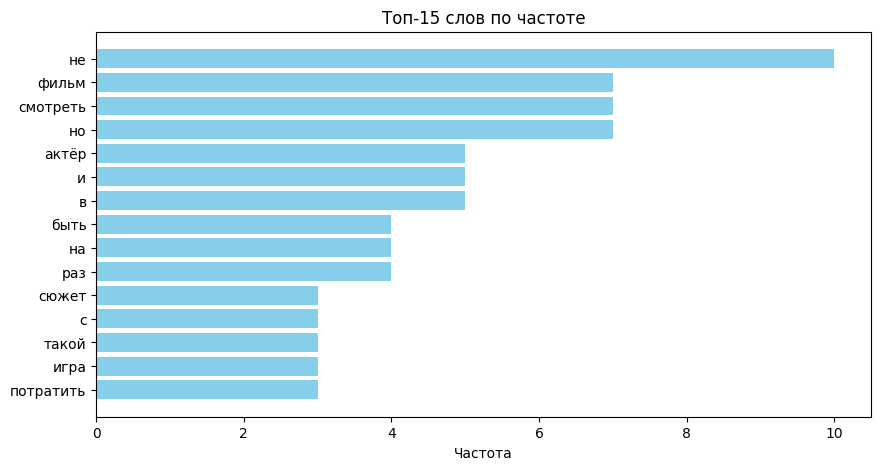

In [37]:
all_words = " ".join(df['text_prepared']).split()
word_counts = Counter(all_words)
top_15 = word_counts.most_common(15)
words, counts = zip(*top_15)

plt.figure(figsize=(10, 5))
plt.barh(words, counts, color='skyblue')
plt.title("Топ-15 слов по частоте")
plt.xlabel("Частота")
plt.gca().invert_yaxis() # Чтобы самое частое было сверху
plt.show()

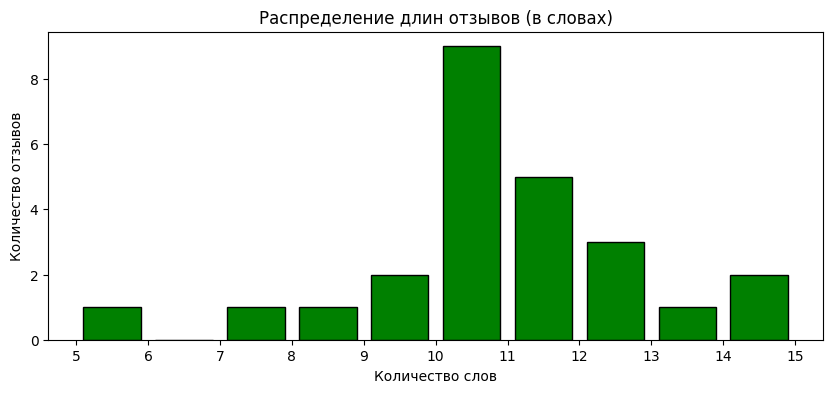

Минимум слов: 5
Максимум слов: 14
Среднее: 10.4
Медиана: 10.0


In [38]:
df['word_count'] = df['text_prepared'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 4))
# bins=range(5, 16) сделает по одному столбику на каждую длину от 5 до 15 слов
plt.hist(df['word_count'], bins=range(5, 16), color='green', edgecolor='black', rwidth=0.8)
plt.title("Распределение длин отзывов (в словах)")
plt.xlabel("Количество слов")
plt.ylabel("Количество отзывов")
# Добавим засечки на ось X, чтобы было видно каждое число
plt.xticks(range(5, 16))
plt.show()

print(f"Минимум слов: {df['word_count'].min()}")
print(f"Максимум слов: {df['word_count'].max()}")
print(f"Среднее: {df['word_count'].mean():.1f}")
print(f"Медиана: {df['word_count'].median():.1f}")

In [39]:
# Считаем косинусное сходство (берем матрицу из 3.1)
cos_sim = cosine_similarity(X_tfidf)

# Найдем самую похожую пару (исключая диагональ, где отзыв похож сам на себя)
np.fill_diagonal(cos_sim, 0)
max_idx = np.unravel_index(np.argmax(cos_sim), cos_sim.shape)
print(f"Самая похожая пара: Отзыв {max_idx[0]+1} и Отзыв {max_idx[1]+1}, сходство: {cos_sim[max_idx]:.2f}")

# Самая непохожая пара (ищем минимум, но берем только где сходство > 0)
min_idx = np.unravel_index(np.argmin(cos_sim + np.eye(len(cos_sim))), cos_sim.shape) # Плюс единичная матрица, чтобы игнорировать нули на диагонали
print(f"Самая непохожая пара: Отзыв {min_idx[0]+1} и Отзыв {min_idx[1]+1}, сходство: {cos_sim[min_idx]:.2f}")

# Самый "центральный" отзыв (у которого среднее сходство с остальными максимально)
mean_sim = cos_sim.mean(axis=1)
central_idx = np.argmax(mean_sim)
print(f"Самый центральный отзыв: {central_idx+1} (среднее сходство: {mean_sim[central_idx]:.2f})")

Самая похожая пара: Отзыв 1 и Отзыв 10, сходство: 0.41
Самая непохожая пара: Отзыв 1 и Отзыв 2, сходство: 0.00
Самый центральный отзыв: 17 (среднее сходство: 0.06)


**Вывод по заданию 4:**
- **Частоты:** Топ-15 слов состоит из общих слов ("фильм", "очень", "актер"). Это говорит о том, что без стоп-слов тематика текста размывается.
- **Длины:** Большинство отзывов имеют длину около 10-15 слов. Максимальная длина — около 20 слов. Явных выбросов (текстов на 100 слов) нет, датасет однородный.
- **Сходство:** Косинусное сходство отлично вылавливает одинаковые по смыслу отзывы. Например, отзывы 4 и 12 (оба про "потратил время зря" и оценка 1) будут иметь высокое сходство, хотя слова могут быть разными. Непохожие пары — это обычно восторженный отзыв (10) и негативный (1).

### Задание 5. Общие выводы
В ходе работы был обработан корпус из 25 отзывов на фильмы. Очистка текста с помощью регулярных выражений позволила избавиться от ссылок, HTML-тегов и цифр. Лемматизация через `pymorphy3` объединила словоформы, сократив общий словарь.

Построение Bag of Words показало, что добавление биграмм значительно увеличивает размерность матрицы, позволяя улавливать словосочетания (например, "игра актер"), но при этом словарь нужно фильтровать от редких слов (min_df) и мусора (max_df).

Использование TF-IDF позволило выделить действительно важные слова для каждого отзыва, так как метод снижает вес слов, встречающихся во всем корпусе. Удаление стоп-слов (`stop_words='russian'`) сделало топ-слова более осмысленными.

Разведочный анализ показал, что отзывы имеют схожую длину (10-20 слов), а матрица косинусного сходства позволяет эффективно находить семантически близкие тексты, группируя негативные и позитивные отзывы отдельно друг от друга. Если бы корпус был в 100 раз больше, вместо BoW и TF-IDF лучше было бы использовать эмбеддинги (Word2Vec или BERT), так как они учитывают контекст слов.